# Exploratory Data Analysis of Used Cars

## Project Introduction

Student Name:Joshua Easo Jacob

Dataset Name:Uncleaned Used Cars Dataset

Dataset File: `uncleaned_used_cars_eda (1).csv`

### Dataset Description

The Used Cars dataset contains information about cars, including brand, model, manufacturing year, price, kilometres driven, fuel type, transmission, ownership type, mileage, engine capacity, city, insurance status, seller rating, and listed date.

The dataset contains real-world automobile information and includes missing values, duplicate records, inconsistent categorical values, and unsuitable data types that need to be cleaned before analysis.

### Project Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on the Used Cars dataset. The analysis aims to understand the structure and quality of the data, clean the dataset, identify patterns and relationships between different car attributes, analyze numerical and categorical variables, detect potential outliers, and derive meaningful insights from the data.

The cleaned dataset will also be used for practicing Linear Regression as part of the learning process.

In [1]:
#library importing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

In [2]:
# Choose the used-cars CSV file from your computer
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print('Shape:', df.shape)
df.head(11)

Saving uncleaned_used_cars_eda.csv to uncleaned_used_cars_eda.csv
Shape: (123, 15)


,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
0,CAR001,maruti,Baleno,2009,236000.0,13300,petrol,manual,1st,12.9,1000.0,hyderabad,Yes,3.1,02/02/2026
1,CAR002,MARUTI,i20,2010,292000.0,17600,Diesel,Automatic,Second,13.8,1200.0,Hyd,Yes,3.2,03/03/2026
2,CAR003,Hyundai,Creta,2011,348000.0,21900,diesel,Auto,2nd,14.7,1400.0,Bangalore,Yes,3.3,2026-04-04
3,CAR004,hyundai,Nexon,2012,404000.0,26200,CNG,AUTOMATIC,Third,15.6,1600.0,Bengaluru,NO,3.4,05/05/2026
4,CAR005,Tata,XUV300,2013,460000.0,30500,Electric,Manual,3rd,16.5,1800.0,Mumbai,Yes,3.5,06/06/2026
5,CAR006,TATA,Seltos,2014,516000.0,34800,PETROL,manual,First,17.4,2000.0,Pune,Yes,3.6,2026-07-07
6,CAR007,Mahindra,Kwid,2015,509000.0,39100,Petrol,Automatic,1st,18.3,2200.0,Chennai,Yes,3.7,08/08/2026
7,CAR008,Kia,Innova,2016,565000.0,43400,petrol,Auto,Second,19.2,800.0,Delhi,NO,3.8,09/09/2026
8,CAR009,Renault,Altroz,2017,621000.0,47700,Diesel,AUTOMATIC,2nd,20.1,1000.0,New Delhi,Yes,3.9,2026-10-10
9,CAR010,Toyota,Swift,2018,677000.0,52000,diesel,Manual,Third,12.0,1200.0,Hyderabad,Yes,4.0,11/11/2026


In [3]:
df.shape

(123, 15)

In [4]:
#displaying all columns
df.columns

Index(['car_id', 'brand', 'model', 'year', 'price_inr', 'km_driven',
       'fuel_type', 'transmission', 'owner_type', 'mileage_kmpl', 'engine_cc',
       'city', 'insurance_valid', 'seller_rating', 'listed_date'],
      dtype='object')

In [5]:
df.dtypes

,0
car_id,object
brand,object
model,object
year,object
price_inr,float64
km_driven,object
fuel_type,object
transmission,object
owner_type,object
mileage_kmpl,float64


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           123 non-null    object 
 1   brand            116 non-null    object 
 2   model            123 non-null    object 
 3   year             123 non-null    object 
 4   price_inr        118 non-null    float64
 5   km_driven        123 non-null    object 
 6   fuel_type        123 non-null    object 
 7   transmission     120 non-null    object 
 8   owner_type       123 non-null    object 
 9   mileage_kmpl     118 non-null    float64
 10  engine_cc        119 non-null    float64
 11  city             123 non-null    object 
 12  insurance_valid  123 non-null    object 
 13  seller_rating    123 non-null    float64
 14  listed_date      123 non-null    object 
dtypes: float64(4), object(11)
memory usage: 14.5+ KB


In [7]:
df.head(11)


,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
0,CAR001,maruti,Baleno,2009,236000.0,13300,petrol,manual,1st,12.9,1000.0,hyderabad,Yes,3.1,02/02/2026
1,CAR002,MARUTI,i20,2010,292000.0,17600,Diesel,Automatic,Second,13.8,1200.0,Hyd,Yes,3.2,03/03/2026
2,CAR003,Hyundai,Creta,2011,348000.0,21900,diesel,Auto,2nd,14.7,1400.0,Bangalore,Yes,3.3,2026-04-04
3,CAR004,hyundai,Nexon,2012,404000.0,26200,CNG,AUTOMATIC,Third,15.6,1600.0,Bengaluru,NO,3.4,05/05/2026
4,CAR005,Tata,XUV300,2013,460000.0,30500,Electric,Manual,3rd,16.5,1800.0,Mumbai,Yes,3.5,06/06/2026
5,CAR006,TATA,Seltos,2014,516000.0,34800,PETROL,manual,First,17.4,2000.0,Pune,Yes,3.6,2026-07-07
6,CAR007,Mahindra,Kwid,2015,509000.0,39100,Petrol,Automatic,1st,18.3,2200.0,Chennai,Yes,3.7,08/08/2026
7,CAR008,Kia,Innova,2016,565000.0,43400,petrol,Auto,Second,19.2,800.0,Delhi,NO,3.8,09/09/2026
8,CAR009,Renault,Altroz,2017,621000.0,47700,Diesel,AUTOMATIC,2nd,20.1,1000.0,New Delhi,Yes,3.9,2026-10-10
9,CAR010,Toyota,Swift,2018,677000.0,52000,diesel,Manual,Third,12.0,1200.0,Hyderabad,Yes,4.0,11/11/2026


In [8]:
df.describe()

,price_inr,mileage_kmpl,engine_cc,seller_rating
count,1.180000e+02,118.000000,119.000000,123.000000
mean,7.984492e+05,16.118644,1507.563025,4.204065
std,8.676712e+05,2.613769,456.805352,1.091127
min,1.890000e+05,12.000000,800.000000,3.000000
25%,4.532500e+05,13.800000,1200.000000,3.600000
50%,7.285000e+05,16.500000,1600.000000,4.100000
75%,9.852500e+05,18.300000,1900.000000,4.550000
max,9.500000e+06,20.100000,2200.000000,8.700000


In [9]:
df.isnull().sum()

,0
car_id,0
brand,7
model,0
year,0
price_inr,5
km_driven,0
fuel_type,0
transmission,3
owner_type,0
mileage_kmpl,5


#duplicate analysis

In [10]:
df.duplicated().sum()

np.int64(3)

In [11]:
df[df.duplicated()]

,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
120,CAR012,Maruti,i20,2020,789000.0,60600,Electric,Automatic,First,13.8,1600.0,Hyd,NO,4.2,2026-01-13
121,CAR038,NaN,Innova,2012,865000.0,39100,diesel,Auto,Second,19.2,2000.0,Delhi,Yes,4.7,12/03/2026
122,CAR075,Hyundai,XUV300,2015,366000.0,64900,Electric,Manual,2nd,16.5,1400.0,Mumbai,Yes,4.2,31/02/2025


In [12]:
df_clean = df.drop_duplicates()

print("Shape before removing duplicates:", df.shape)
print("Shape after removing duplicates:", df_clean.shape)

Shape before removing duplicates: (123, 15)
Shape after removing duplicates: (120, 15)


#data cleaning and analyzing

In [13]:
df_clean["brand"].value_counts(dropna=False)

,count
brand,
maruti,10
Hyundai,10
Tata,10
Toyota,10
Kia,10
Maruti,10
MARUTI,9
hyundai,9
TATA,9


In [14]:
df_clean['fuel_type'].value_counts(dropna=False)


,count
fuel_type,
petrol,18
Diesel,17
diesel,17
CNG,17
Electric,17
PETROL,17
Petrol,17


In [15]:
df_clean['transmission'].value_counts(dropna=False)

,count
transmission,
Manual,24
AUTOMATIC,24
Automatic,23
manual,23
Auto,23
NaN,3


In [16]:
df_clean['owner_type'].value_counts(dropna=False)

,count
owner_type,
1st,20
Second,20
2nd,20
Third,20
3rd,20
First,20


In [17]:
df_clean['city'].value_counts(dropna=False)


,count
city,
hyderabad,12
Hyd,12
Bangalore,12
Bengaluru,12
Mumbai,12
Pune,12
Chennai,12
Delhi,12
New Delhi,12


In [18]:
df_clean["insurance_valid"].value_counts(dropna=False)

,count
insurance_valid,
Yes,80
NO,27
Yes,13


In [19]:
df_clean["year"].value_counts(dropna=False)

,count
year,
2009,8
2010,7
2012,7
2013,7
2016,7
2015,7
2017,7
2022,7
2020,7


In [20]:
df_clean["km_driven"].value_counts(dropna=False)

,count
km_driven,
13300,4
17600,4
21900,4
26200,4
30500,4
34800,4
39100,4
43400,4
47700,4


In [21]:
df_clean.describe()

,price_inr,mileage_kmpl,engine_cc,seller_rating
count,1.150000e+02,115.000000,116.000000,120.000000
mean,8.017130e+05,16.108696,1503.448276,4.200000
std,8.780515e+05,2.622927,460.232651,1.103851
min,1.890000e+05,12.000000,800.000000,3.000000
25%,4.555000e+05,13.800000,1150.000000,3.575000
50%,7.240000e+05,16.500000,1500.000000,4.050000
75%,9.925000e+05,18.300000,1850.000000,4.525000
max,9.500000e+06,20.100000,2200.000000,8.700000


In [22]:
df_clean[df_clean["seller_rating"] > 5]

,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
21,CAR022,Toyota,i20,2013,1223000.0,103600,petrol,Automatic,Third,13.8,2000.0,Hyd,Yes,8.7,23/11/2026
43,CAR044,Kia,Nexon,2018,1138000.0,64900,Diesel,AUTOMATIC,Second,15.6,1600.0,Bengaluru,NO,8.7,18/09/2026
65,CAR066,TATA,Seltos,2023,1053000.0,26200,diesel,manual,First,17.4,1200.0,Pune,Yes,8.7,2026-07-13
87,CAR088,hyundai,Innova,2011,968000.0,650000,CNG,Auto,Third,19.2,800.0,Delhi,NO,8.7,08/05/2026
109,CAR110,MARUTI,Swift,2016,883000.0,82100,Electric,Manual,Second,12.0,2000.0,Hyderabad,Yes,8.7,03/03/2026


In [23]:
df_clean["brand"]=df_clean["brand"].str.strip().str.title()


/tmp/ipykernel_1058/4099753152.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["brand"]=df_clean["brand"].str.strip().str.title()


In [24]:
# Correct the spelling inconsistency in brand

df_clean["brand"] = df_clean["brand"].replace("Toyta", "Toyota")

/tmp/ipykernel_1058/2812460567.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["brand"] = df_clean["brand"].replace("Toyta", "Toyota")


In [25]:
df_clean["brand"].value_counts(dropna=False)

,count
brand,
Maruti,29
Hyundai,19
Tata,19
Toyota,19
Kia,10
Mahindra,9
Renault,9
NaN,6


In [26]:
# Standardize fuel type labels

df_clean["fuel_type"] = df_clean["fuel_type"].str.strip().str.title()

/tmp/ipykernel_1058/4194598309.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["fuel_type"] = df_clean["fuel_type"].str.strip().str.title()


In [27]:
df_clean["fuel_type"].value_counts(dropna=False)


,count
fuel_type,
Petrol,52
Diesel,34
Cng,17
Electric,17


In [28]:
# Standardize transmission labels

df_clean["transmission"] = df_clean["transmission"].str.strip().str.title()

/tmp/ipykernel_1058/844579119.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["transmission"] = df_clean["transmission"].str.strip().str.title()


In [29]:
df_clean["transmission"].value_counts(dropna=False)

,count
transmission,
Manual,47
Automatic,47
Auto,23
NaN,3


In [30]:
df_clean["transmission"]=df_clean["transmission"].replace("Auto","Automatic")

/tmp/ipykernel_1058/1457158296.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["transmission"]=df_clean["transmission"].replace("Auto","Automatic")


In [31]:
df_clean["transmission"].value_counts(dropna=False)

,count
transmission,
Automatic,70
Manual,47
NaN,3


In [32]:
print(df_clean["brand"].value_counts(dropna=False))
print(df_clean["fuel_type"].value_counts(dropna=False))
print(df_clean["transmission"].value_counts(dropna=False))

brand
Maruti      29
Hyundai     19
Tata        19
Toyota      19
Kia         10
Mahindra     9
Renault      9
NaN          6
Name: count, dtype: int64
fuel_type
Petrol      52
Diesel      34
Cng         17
Electric    17
Name: count, dtype: int64
transmission
Automatic    70
Manual       47
NaN           3
Name: count, dtype: int64


In [33]:
df_clean["owner_type"].value_counts(dropna=False)

,count
owner_type,
1st,20
Second,20
2nd,20
Third,20
3rd,20
First,20


In [34]:
df_clean["owner_type"] = df_clean["owner_type"].replace({
    "1st": "First",
    "2nd": "Second",
    "3rd": "Third"
})

/tmp/ipykernel_1058/4052782041.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["owner_type"] = df_clean["owner_type"].replace({


In [35]:
df_clean["owner_type"].value_counts(dropna=False)

,count
owner_type,
First,40
Second,40
Third,40


In [36]:
# Convert all owner type categories into numerical values

df_clean["owner_type"] = df_clean["owner_type"].replace({
    "1st": 1,
    "First": 1,
    "2nd": 2,
    "Second": 2,
    "3rd": 3,
    "Third": 3
})

/tmp/ipykernel_1058/1606311769.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean["owner_type"] = df_clean["owner_type"].replace({
/tmp/ipykernel_1058/1606311769.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["owner_type"] = df_clean["owner_type"].replace({


In [37]:
df_clean["owner_type"].value_counts(dropna=False)

,count
owner_type,
1,40
2,40
3,40


In [38]:
df_clean["city"] = df_clean["city"].replace({
    "hyderabad": "Hyderabad",
    "Hyd": "Hyderabad",
    "Bangalore": "Bengaluru",
    "New Delhi": "Delhi"
})

/tmp/ipykernel_1058/3720684603.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["city"] = df_clean["city"].replace({


In [39]:
df_clean["city"].value_counts(dropna=False)

,count
city,
Hyderabad,36
Bengaluru,24
Delhi,24
Mumbai,12
Pune,12
Chennai,12


In [40]:
df_clean["insurance_valid"] = df_clean["insurance_valid"].str.strip().str.title()

/tmp/ipykernel_1058/476125234.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["insurance_valid"] = df_clean["insurance_valid"].str.strip().str.title()


In [41]:
df_clean["insurance_valid"].value_counts()

,count
insurance_valid,
Yes,93
No,27


In [42]:
df_clean["year"]= pd.to_numeric(df_clean["year"], errors="coerce")

/tmp/ipykernel_1058/71146584.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["year"]= pd.to_numeric(df_clean["year"], errors="coerce")


In [43]:
df_clean["year"].isnull().sum()

np.int64(4)

In [44]:
df_clean["year"] = df_clean["year"].fillna(df_clean["year"].median())

/tmp/ipykernel_1058/3826312912.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["year"] = df_clean["year"].fillna(df_clean["year"].median())


In [45]:
df_clean['km_driven'].value_counts()

,count
km_driven,
13300,4
17600,4
21900,4
26200,4
30500,4
34800,4
39100,4
43400,4
47700,4


In [46]:
df_clean["km_driven"] = df_clean["km_driven"].astype(str).str.replace(" km", "", regex=False)
df_clean["km_driven"] = pd.to_numeric(df_clean["km_driven"], errors="coerce")

/tmp/ipykernel_1058/3808503166.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["km_driven"] = df_clean["km_driven"].astype(str).str.replace(" km", "", regex=False)
/tmp/ipykernel_1058/3808503166.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["km_driven"] = pd.to_numeric(df_clean["km_driven"], errors="coerce")


In [47]:
df_clean[df_clean["km_driven"] < 0]

,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
48,CAR049,Maruti,Altroz,2023.0,227000.0,-1200,Petrol,Automatic,1,20.1,1000.0,Delhi,Yes,3.7,23/02/2026


In [48]:
df_clean.loc[df_clean["km_driven"] < 0, "km_driven"] = df_clean["km_driven"].median()

In [49]:
df_clean["km_driven"].value_counts()

,count
km_driven,
13300,4
17600,4
21900,4
26200,4
30500,4
34800,4
39100,4
43400,4
47700,4


In [50]:
df_clean["price_inr"] = df_clean["price_inr"].fillna(df_clean["price_inr"].median())
df_clean["mileage_kmpl"] = df_clean["mileage_kmpl"].fillna(df_clean["mileage_kmpl"].median())
df_clean["engine_cc"] = df_clean["engine_cc"].fillna(df_clean["engine_cc"].median())
df_clean["brand"] = df_clean["brand"].fillna(df_clean["brand"].mode()[0])
df_clean["transmission"] = df_clean["transmission"].fillna(df_clean["transmission"].mode()[0])

/tmp/ipykernel_1058/1074718374.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["price_inr"] = df_clean["price_inr"].fillna(df_clean["price_inr"].median())
/tmp/ipykernel_1058/1074718374.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["mileage_kmpl"] = df_clean["mileage_kmpl"].fillna(df_clean["mileage_kmpl"].median())
/tmp/ipykernel_1058/1074718374.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer

In [51]:
df_clean["seller_rating"] = df_clean["seller_rating"].fillna(df_clean["seller_rating"].median())

/tmp/ipykernel_1058/3688863869.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["seller_rating"] = df_clean["seller_rating"].fillna(df_clean["seller_rating"].median())


In [52]:
df_clean["listed_date"] = pd.to_datetime(df_clean["listed_date"], errors="coerce")

/tmp/ipykernel_1058/403266500.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["listed_date"] = pd.to_datetime(df_clean["listed_date"], errors="coerce")


In [53]:
print("Final Shape:", df_clean.shape)


Final Shape: (120, 15)


In [54]:
print(df_clean.isnull().sum())


car_id              0
brand               0
model               0
year                0
price_inr           0
km_driven           0
fuel_type           0
transmission        0
owner_type          0
mileage_kmpl        0
engine_cc           0
city                0
insurance_valid     0
seller_rating       0
listed_date        80
dtype: int64


In [55]:
df_clean["listed_date"] = pd.to_datetime(
    df_clean["listed_date"],
    errors="coerce",
    dayfirst=True
)

/tmp/ipykernel_1058/3786313225.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["listed_date"] = pd.to_datetime(


In [56]:
print(df_clean.duplicated().sum())


0


In [57]:
print(df_clean.dtypes)

car_id                     object
brand                      object
model                      object
year                      float64
price_inr                 float64
km_driven                   int64
fuel_type                  object
transmission               object
owner_type                  int64
mileage_kmpl              float64
engine_cc                 float64
city                       object
insurance_valid            object
seller_rating             float64
listed_date        datetime64[ns]
dtype: object


In [58]:
df_clean["listed_date"].isnull().sum()

np.int64(80)

In [59]:
df_clean["listed_date"] = df_clean["listed_date"].fillna(
    df_clean["listed_date"].median()
)

/tmp/ipykernel_1058/1675386825.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["listed_date"] = df_clean["listed_date"].fillna(


In [60]:
df_clean["listed_date"].isnull().sum()

np.int64(0)

# EDA charts


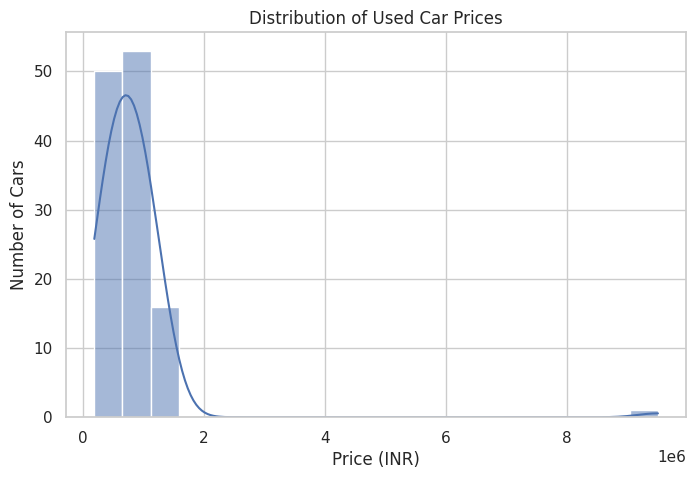

In [61]:
plt.figure(figsize=(8,5))
sns.histplot(df_clean["price_inr"], bins=20, kde=True)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Number of Cars")
plt.show()

Most used cars are concentrated in the lower price range, while a small number of high-priced cars create a strong right-skewed distribution.

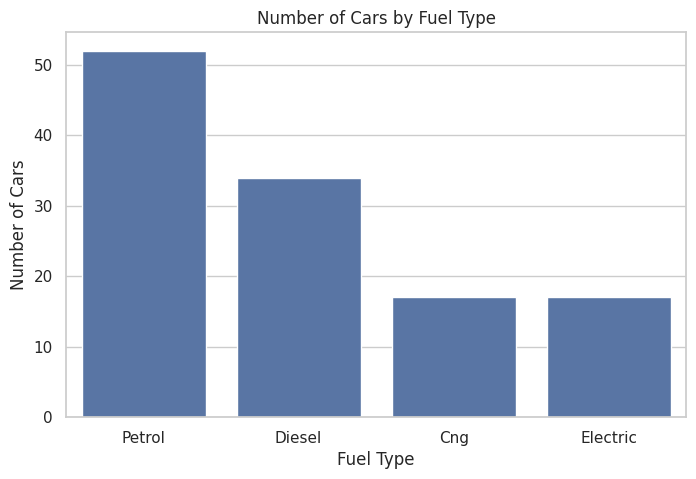

In [62]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_clean, x="fuel_type")

plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.show()

Observation: Petrol cars form the largest group in the dataset, followed by diesel, CNG, and electric cars.

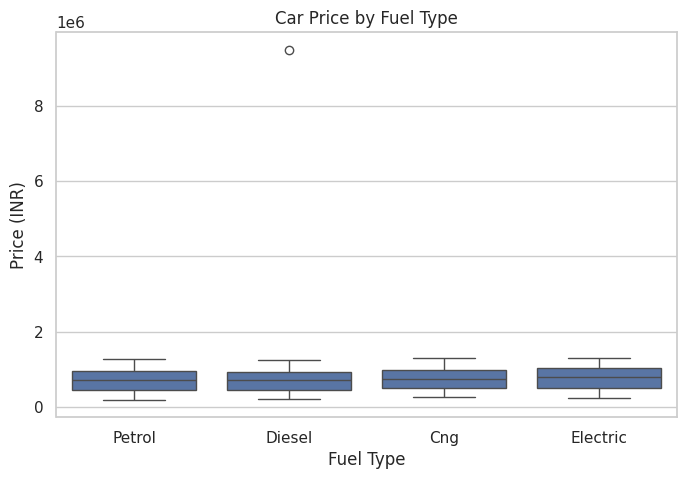

In [63]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean, x="fuel_type", y="price_inr")

plt.title("Car Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price (INR)")
plt.show()

Car prices show broadly similar distributions across fuel types, but the diesel category contains a notable high-price outlier.

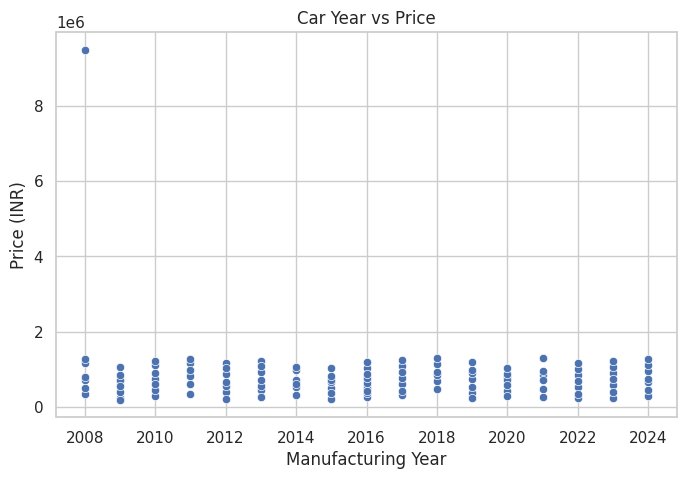

In [64]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean, x="year", y="price_inr")

plt.title("Car Year vs Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Price (INR)")
plt.show()

Car prices are distributed across different manufacturing years, with most observations concentrated below ₹1.5 million. One unusually high-priced car appears as a clear outlier.

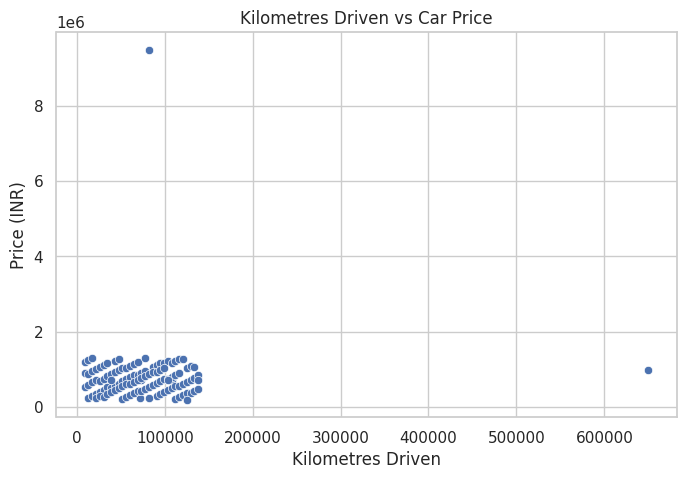

In [65]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean, x="km_driven", y="price_inr")

plt.title("Kilometres Driven vs Car Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Price (INR)")
plt.show()

most cars have kilometres driven below approximately 150,000 km, while a few observations show unusually high mileage. The relationship between kilometres driven and price is not clearly linear in this dataset.

In [66]:
numeric_cols = df.select_dtypes(include = "number")
print(numeric_cols)

     price_inr  mileage_kmpl  engine_cc  seller_rating
0     236000.0          12.9     1000.0            3.1
1     292000.0          13.8     1200.0            3.2
2     348000.0          14.7     1400.0            3.3
3     404000.0          15.6     1600.0            3.4
4     460000.0          16.5     1800.0            3.5
..         ...           ...        ...            ...
118  1261000.0          20.1     2200.0            4.4
119   189000.0          12.0      800.0            4.5
120   789000.0          13.8     1600.0            4.2
121   865000.0          19.2     2000.0            4.7
122   366000.0          16.5     1400.0            4.2

[123 rows x 4 columns]


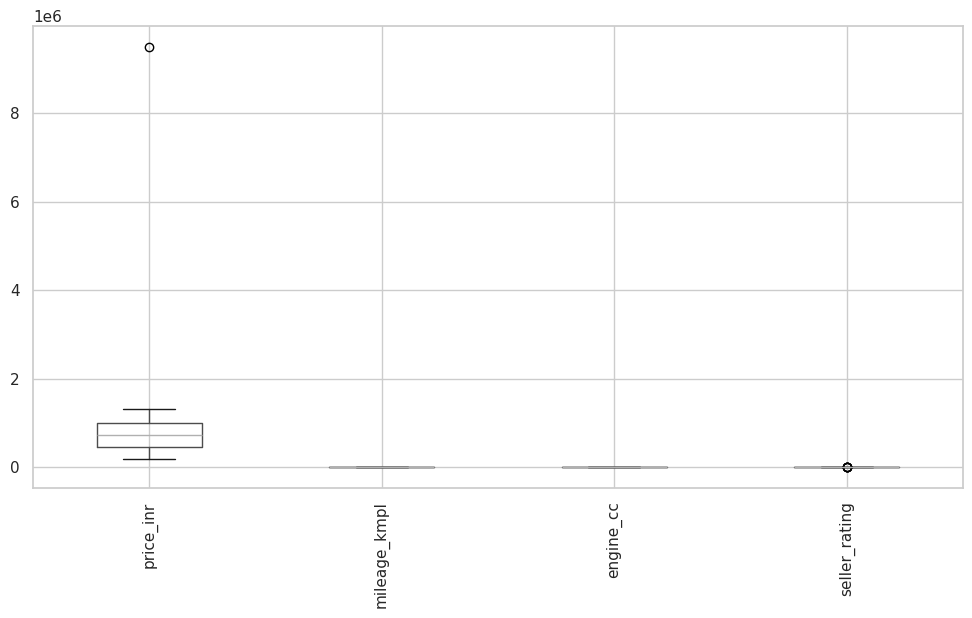

In [67]:
numeric_cols.boxplot(figsize =(12,6))
plt.xticks(rotation = 90)
plt.show()

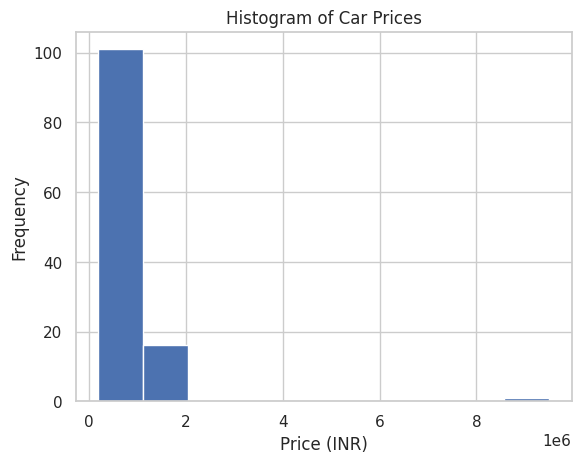

In [68]:
# Univariate

import matplotlib.pyplot as plt

df["price_inr"].hist(bins = 10)

plt.title("Histogram of Car Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Frequency")
plt.show()



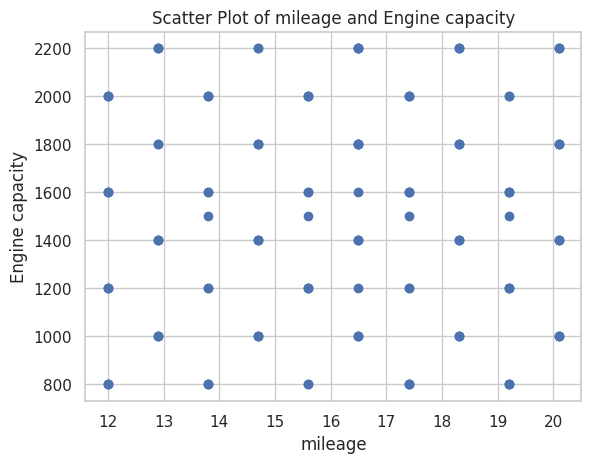

In [69]:
#Bivariate

plt.scatter(df_clean["mileage_kmpl"], df_clean["engine_cc"])


plt.title("Scatter Plot of mileage and Engine capacity")

plt.xlabel("mileage")

plt.ylabel("Engine capacity")

plt.show()

Observation: The scatter plot shows the relationship between mileage and engine capacity. The points are distributed across different engine capacities and mileage values, indicating variation between the two variables.

#Correlation heatmap

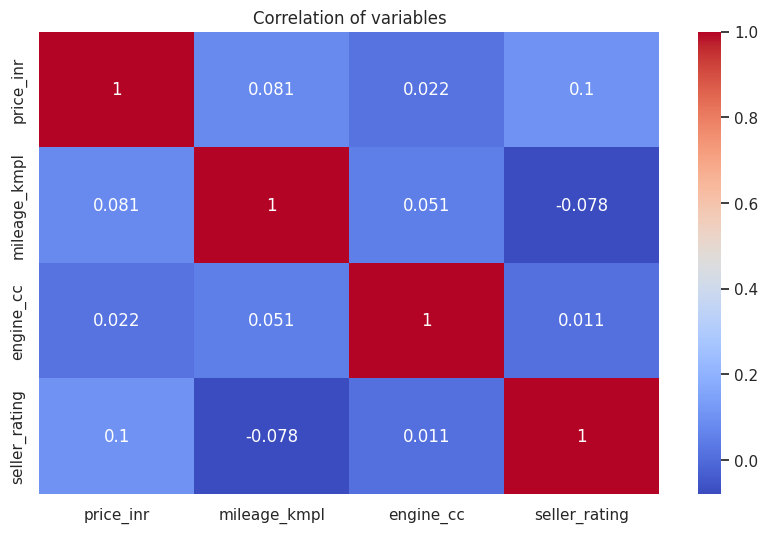

In [70]:
corr = df.corr(numeric_only = True)

plt.figure(figsize= (10,6))

sns.heatmap(corr, annot = True, cmap = "coolwarm")

plt.title("Correlation of variables")

plt.show()

The correlation matrix shows very weak linear relationships among the numerical variables. In particular, price has only a weak correlation with mileage, engine capacity, and seller rating.

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           123 non-null    object 
 1   brand            116 non-null    object 
 2   model            123 non-null    object 
 3   year             123 non-null    object 
 4   price_inr        118 non-null    float64
 5   km_driven        123 non-null    object 
 6   fuel_type        123 non-null    object 
 7   transmission     120 non-null    object 
 8   owner_type       123 non-null    object 
 9   mileage_kmpl     118 non-null    float64
 10  engine_cc        119 non-null    float64
 11  city             123 non-null    object 
 12  insurance_valid  123 non-null    object 
 13  seller_rating    123 non-null    float64
 14  listed_date      123 non-null    object 
dtypes: float64(4), object(11)
memory usage: 14.5+ KB


In [72]:
df_clean['insurance_valid'].value_counts()

,count
insurance_valid,
Yes,93
No,27


In [73]:
df["insurance_valid"]= (df["insurance_valid"].map({"Yes":1, "No":0}))

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           123 non-null    object 
 1   brand            116 non-null    object 
 2   model            123 non-null    object 
 3   year             123 non-null    object 
 4   price_inr        118 non-null    float64
 5   km_driven        123 non-null    object 
 6   fuel_type        123 non-null    object 
 7   transmission     120 non-null    object 
 8   owner_type       123 non-null    object 
 9   mileage_kmpl     118 non-null    float64
 10  engine_cc        119 non-null    float64
 11  city             123 non-null    object 
 12  insurance_valid  82 non-null     float64
 13  seller_rating    123 non-null    float64
 14  listed_date      123 non-null    object 
dtypes: float64(5), object(10)
memory usage: 14.5+ KB


In [75]:
df_clean['insurance_valid'].dtype

dtype('O')

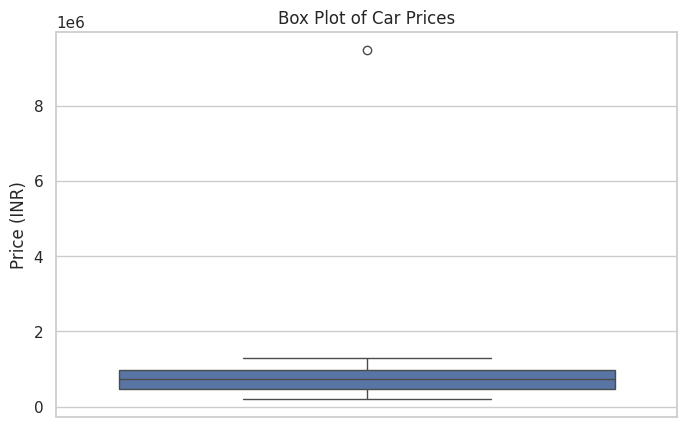

In [78]:
#Outlier Analysis
plt.figure(figsize=(8,5))

sns.boxplot(y=df_clean["price_inr"])

plt.title("Box Plot of Car Prices")
plt.ylabel("Price (INR)")
plt.show()

## Key Findings

1. The dataset contains 123 original records and 15 variables. After removing duplicate records, the dataset contains 120 records.

2. The dataset contained missing values in several columns, including brand, price, transmission, mileage, and engine capacity. These were handled using appropriate imputation methods.

3. Several categorical variables contained inconsistent labels due to differences in capitalization, spelling, or naming conventions. These were standardized during cleaning.

4. Used-car prices show considerable variation, with some high-priced observations appearing as potential outliers.

5. Fuel type, brand, manufacturing year, mileage, engine capacity, and kilometres driven show varying relationships with car prices.

6. The correlation analysis shows that numerical car characteristics do not all have the same strength of relationship with price.

7. The dataset contains unusual records, such as extremely high kilometres driven and invalid seller-rating values, which highlight the importance of data-quality checks.

## Limitations

- The dataset contains only 123 original records, which is relatively small for drawing broad conclusions about the used-car market.
- Some records contain inconsistent or unusual values.
- The dataset may not represent the entire used-car market.
- Brand-model inconsistencies may affect some analyses wrong car models with different brandss.
- The findings describe patterns within this dataset and should not be generalized to all used cars.


Conclusion

The EDA provided an understanding of the structure, quality, distributions, and relationships within the used-car dataset. Data cleaning improved consistency by handling duplicates, missing values, inconsistent categorical labels, invalid values, and unsuitable data types. The analysis revealed substantial variation in used-car prices and relationships among different vehicle characteristics. Linear Regression was also practiced as an introductory machine-learning model. Its test performance was weak, suggesting that a simple linear relationship was not sufficient to accurately predict prices in this dataset.